# Ortho views → 3D memory → FPV guide: sparse voxels and 3DGS (hi-fi MultiCar)

This notebook builds a **3D memory of the visited scene from the Top, Side and Rear orthographic views only**, then reads it out as a **guide image in the FPV camera**. A world model would take that guide as an extra, pixel-aligned context frame.

One memory, two ways to read it:
- **A. Sparse voxels**, drawn as points with a depth buffer.
- **B. 3DGS + sparse voxels**: the same voxels drawn as 3D Gaussians with alpha compositing.

```
Top / Side / Rear at step t (224 x 224)
   |  what's solid: car (Godot mask), tree canopy (Top colour rule), not-sky (Side/Rear colour rule)
   v
carve a dense box around the car            per-step scratch grid, ~4.7M cells of 0.25 m
   |  colour each cell from the view that sees it first
   v
sparse voxel memory (world-keyed)           write + erase every step; the moving car is never stored
   |
   +-- A: point splats + depth buffer  --+
   +-- B: 3D Gaussians, EWA + blending --+--> FPV guide (224 x 224)
```

**No network is trained anywhere here**, and nothing is fitted per scene: every step is geometry.

**Inputs we treat as given (privileged):**
- **Camera poses:** the camera dicts the exporter sends Godot. A world model would need a learned pose head here.
- **The car mask:** Godot's object-ID mask, the only object MultiCar registers.

The two colour rules stand in for learned mask heads. The data is the hi-fi Godot twin of MultiCar Racing, driven by the same PPO agent as the training data.

## 0. Setup

In [1]:
import os, sys, math, time, warnings
warnings.filterwarnings("ignore")
# The notebook lives in ortho/; work from the repo root so hifi/ and checkpoints/ resolve
if os.path.basename(os.getcwd()) == "ortho":
    os.chdir("..")
sys.path.insert(0, os.path.abspath("ortho"))
sys.path.insert(0, os.path.abspath("hifi"))

import numpy as np
import cv2
import torch
import matplotlib.pyplot as plt
from huggingface_sb3 import load_from_hub
from stable_baselines3 import PPO
from data_rollout import _skip_intro
from wrappers import make_hifi_env
from exporters.base import project as exporter_project

ENV = "MultiCar Racing"
S = 224          # every view at the world model's resolution, S x S
VOXEL = 0.25     # memory cell size in metres
H_MAX = 24.0     # height of the carving box in metres
dev = torch.device("cuda" if torch.cuda.is_available() else "cpu")
np.random.seed(0)

plt.rcParams.update({"figure.dpi": 100, "axes.titlesize": 9})
ASPECT = 0.8     # Godot draws 5:4 frames that get squashed to S x S; display them at 5:4 again

def show(images, titles, size=3.0):
    fig, ax = plt.subplots(1, len(images), figsize=(size * len(images), size * 0.8))
    for a, im, t in zip(np.atleast_1d(ax), images, titles):
        a.imshow(im, aspect=ASPECT); a.set_title(t); a.axis("off")
    plt.tight_layout(); plt.show()

def to_np(img):
    """torch (S, S, 3) in [0, 1] -> uint8 numpy image"""
    return (img.clamp(0, 1).cpu().numpy() * 255).astype(np.uint8)

print("device:", dev, torch.cuda.get_device_name(0) if dev.type == "cuda" else "")

Gym has been unmaintained since 2022 and does not support NumPy 2.0 amongst other critical functionality.
Please upgrade to Gymnasium, the maintained drop-in replacement of Gym, or contact the authors of your software and request that they upgrade.
Users of this version of Gym should be able to simply replace 'import gym' with 'import gymnasium as gym' in the vast majority of cases.
See the migration guide at https://gymnasium.farama.org/introduction/migration_guide/ for additional information.


device: cuda NVIDIA GeForce RTX 3070


## 1. Collect a hi-fi trajectory

The agent drives for 60 steps with the FPV camera facing forward (`"Center"`), then for 24 steps of `"Right"`. Each `"Right"` orbits the camera by 8°, so it ends up at about 190°, **looking back** at track the car has already driven over. That's where a memory should help.

For every step we keep:
- the four views at 224 × 224;
- the car mask in each view;
- the depth of each view (Godot's depth output, metres along the view; used only to build View2Vox's training labels in section 2);
- the four camera dicts (`pos`, `look`, `up`, and `size` or `fov`), exactly as Godot used them.

**A Godot window opens while this cell runs** (about 10 s for 84 steps on the RTX 3070).

[hifi] waiting for Godot on port 36789 ...


84 steps in 10.3 s | Godot draws 750x600, we keep 224x224 | final camera yaw 192 deg


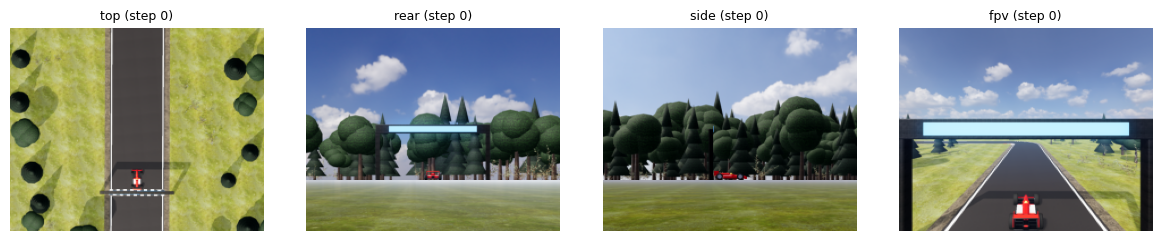

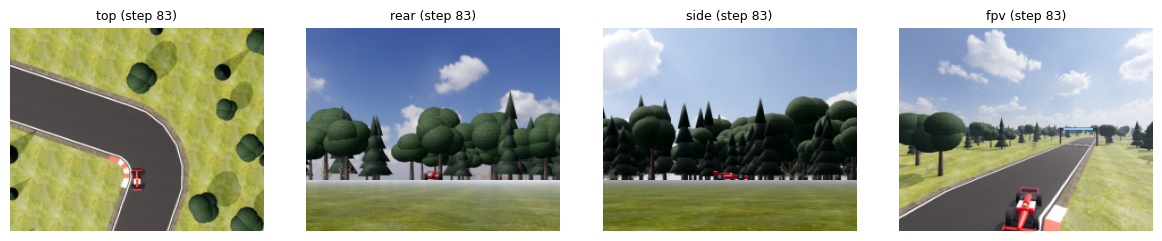

In [2]:
env = make_hifi_env(ENV, aov=("rgb", "mask", "depth"))   # starts Godot
RENDER_W, RENDER_H = env.exporter.size              # 750 x 600: what Godot draws before the wrapper resizes
agent = PPO.load(load_from_hub(repo_id="igpaub/ppo-CarRacing-v2", filename="ppo-CarRacing-v2.zip"),
                 custom_objects={"learning_rate": 0.0, "lr_schedule": lambda _: 0.0, "clip_range": lambda _: 0.0})
VIEWS = ("top", "rear", "side", "fpv")              # the order render() returns them in

obs, _ = env.reset(seed=0)
obs = _skip_intro(env, ENV, obs)
poses = ["Center"] * 60 + ["Right"] * 24
traj, t0 = [], time.time()
for pose in poses:
    action, _ = agent.predict(obs, deterministic=True)
    obs, _, term, trunc, _ = env.step(action)
    frames = env.render(camera_pose=pose)
    car = env.render_masks("car")                    # Godot object-ID masks, same view order
    traj.append(dict(
        pose=pose, yaw=env.cam_yaw,
        cams={c["view"]: c for c in env.exporter.cameras(env.env)},    # the dicts Godot just rendered with
        img={v: cv2.resize(f, (S, S), interpolation=cv2.INTER_AREA) for v, f in zip(VIEWS, frames)},
        car={v: cv2.resize(m, (S, S), interpolation=cv2.INTER_NEAREST) > 0 for v, m in zip(VIEWS, car)},
        depth={v: cv2.resize(env.last_depth[v], (S, S), interpolation=cv2.INTER_NEAREST) for v in VIEWS}))
    if term or trunc:
        break
env.close()
LAST = len(traj) - 1
print(f"{len(traj)} steps in {time.time() - t0:.1f} s | Godot draws {RENDER_W}x{RENDER_H}, we keep {S}x{S} | "
      f"final camera yaw {math.degrees(traj[-1]['yaw']):.0f} deg")
for k in (0, LAST):
    show([traj[k]["img"][v] for v in VIEWS], [f"{v} (step {k})" for v in VIEWS])

## 2. View2Vox: learn Top / Side / Rear → voxels from Godot depth

**View2Vox** sees only the three orthographic images (128 × 128 each). For every cell of a 64 × 64 × 32 grid laid on the Top view (about 1 m across, 0.5 m tall), it predicts whether the cell is solid and what colour it is.

- **Labels come from Godot's depth output**, during training only. Every Top/Side/Rear pixel that hits something becomes a 3D surface point. The cells those points fall in are solid and take the pixel's colour. This is the only place the camera dicts are used.
- **How the views line up is learned.** Top already lies on the grid. Each Side/Rear image axis is mapped onto a grid axis by a learned matrix, which is where the model picks up the "six numbers".
- **Train on three new tracks (seeds 1–3), test on section 1's track (seed 0),** which the model never sees.

In [3]:
import torch.nn as nn
import torch.nn.functional as F

G, NH, DH = 64, 32, 0.5          # grid on the Top view: 64 x 64 cells, 32 height layers of 0.5 m (inputs are 2G = 128 px)

def axes(cam):
    """Camera position and its forward, right and up axes, from a camera dict."""
    pos, look, up = (np.array(cam[k], float) for k in ("pos", "look", "up"))
    fwd = (look - pos) / np.linalg.norm(look - pos)
    right = np.cross(fwd, up); right /= np.linalg.norm(right)
    return pos, fwd, right, np.cross(right, fwd)

def ortho_to_world(cam, row, col, depth):
    """Pixels (row, col) of an S x S orthographic view, `depth` metres along its viewing axis -> world points."""
    pos, fwd, right, up = axes(cam)
    k = RENDER_H / cam["size"]                                       # render pixels per metre
    x = ((col + 0.5) * RENDER_W / S - RENDER_W / 2) / k
    y = (RENDER_H / 2 - (row + 0.5) * RENDER_H / S) / k
    return pos + x[:, None] * right + y[:, None] * up + depth[:, None] * fwd

def world_to_grid(top_cam, P):
    """World points -> grid cell (i, j, k) = (Top row, Top column, height layer)."""
    pos, fwd, right, up = axes(top_cam)
    k = RENDER_H / top_cam["size"]
    row = (RENDER_H / 2 - (P - pos) @ up * k) * S / RENDER_H         # position in the Top image, in pixels
    col = (RENDER_W / 2 + (P - pos) @ right * k) * S / RENDER_W
    return np.floor(row * G / S).astype(int), np.floor(col * G / S).astype(int), np.floor(P[:, 1] / DH).astype(int)

def voxel_labels(r):
    """Training labels from Godot depth: every Top / Side / Rear pixel that hits something is a 3D surface point;
    a grid cell is solid if a point falls in it, and takes that pixel's colour."""
    occ, col = np.zeros((G, G, NH), bool), np.zeros((G, G, NH, 3), np.uint8)
    for v in ("side", "rear", "top"):                       # Top last, so its colour wins where views overlap
        rows, cols = np.nonzero(r["depth"][v] < r["cams"][v]["far"] - 0.5)      # pixels that hit something
        P = ortho_to_world(r["cams"][v], rows, cols, r["depth"][v][rows, cols])
        i, j, k = world_to_grid(r["cams"]["top"], P)
        k = np.maximum(k, 0)                                                     # the ground sits at height 0
        ok = (i >= 0) & (i < G) & (j >= 0) & (j < G) & (k < NH)
        occ[i[ok], j[ok], k[ok]] = True
        col[i[ok], j[ok], k[ok]] = r["img"][v][rows[ok], cols[ok]]
    return occ, col

def views(r):
    """The model's only input: Top, Side and Rear at 128 x 128 -> tensor (3 views, 3 colours, 128, 128)."""
    return torch.tensor(np.stack([cv2.resize(r["img"][v], (2 * G, 2 * G), interpolation=cv2.INTER_AREA)
                                  for v in ("top", "side", "rear")])).permute(0, 3, 1, 2).float() / 255

### Training data: three new tracks

**A Godot window opens again** (about a minute for 360 steps, with depth).

In [4]:
env = make_hifi_env(ENV, aov=("rgb", "depth"))
data, t0 = [], time.time()
for seed in (1, 2, 3):                                 # three new tracks; section 1's track (seed 0) stays unseen
    obs, _ = env.reset(seed=seed)
    obs = _skip_intro(env, ENV, obs)
    for _ in range(120):
        action, _ = agent.predict(obs, deterministic=True)
        obs, _, term, trunc, _ = env.step(action)
        frames = env.render(camera_pose="Center")
        
        r = dict(cams={c["view"]: c for c in env.exporter.cameras(env.env)},
                 img={v: cv2.resize(f, (S, S), interpolation=cv2.INTER_AREA) for v, f in zip(VIEWS, frames)},
                 depth={v: cv2.resize(env.last_depth[v], (S, S), interpolation=cv2.INTER_NEAREST) for v in VIEWS})
        
        data.append((views(r), *voxel_labels(r)))
        if term or trunc:
            break
env.close()
X = torch.stack([d[0] for d in data])                  # (N, 3 views, 3, 64, 64)
Y = torch.tensor(np.stack([d[1] for d in data]))       # (N, 64, 64, 32) solid or not
C = torch.tensor(np.stack([d[2] for d in data]))       # (N, 64, 64, 32, 3) colour, uint8
print(f"{len(data)} samples in {time.time() - t0:.0f} s | solid cells {Y.float().mean():.1%} "
      f"(above the ground {Y[..., 1:].float().mean():.2%})")

[hifi] waiting for Godot on port 44609 ...


360 samples in 39 s | solid cells 4.4% (above the ground 1.52%)


### The model

1. **One small residual CNN per view** turns each 128 × 128 image into a 64 × 64 feature map.
2. **The three maps are spread into the 3D grid:**
   - Top fills every height of its column.
   - Side and Rear fill every cell along the axis they look down.

   First, each grid row, column and height layer reads a **soft mix of Side or Rear pixels** (a softmax over that image axis). It starts as a plain resize, and training learns MultiCar's actual line-up.
3. **A small 3D U-Net** goes one step down to 32 × 32 × 16 to see wider context, then back up. It outputs, for each cell, "solid?" and three view weights.
4. **Colour isn't invented:** each cell takes a weighted mix of the colours that Top, Side and Rear show at it. The colour loss counts only solid cells.

Training uses half-precision maths (bfloat16) to run about twice as fast.

In [5]:
class Res(nn.Module):
    """Residual block, 2D or 3D: x + conv(relu(conv(relu(x))))."""
    def __init__(self, c, conv):
        super().__init__()
        self.a, self.b = conv(c, c, 3, padding=1), conv(c, c, 3, padding=1)

    def forward(self, x):
        return x + self.b(F.relu(self.a(F.relu(x))))

class View2Vox(nn.Module):
    """Top / Side / Rear (128 x 128) -> solid-cell logit and colour on Top's 64 x 64 grid x 32 height layers."""
    def __init__(self, c=64):
        super().__init__()
        cnn = lambda: nn.Sequential(nn.Conv2d(3, c, 4, stride=2, padding=1), Res(c, nn.Conv2d), Res(c, nn.Conv2d), Res(c, nn.Conv2d))
        self.top, self.side, self.rear = cnn(), cnn(), cnn()                  # each: 128 x 128 image -> 64 x 64 features
        flip = torch.eye(G).flip(0)                                            # line-up logits; softmax(10 * resize) ~= resize
        self.side_cols = nn.Parameter(10 * flip)                               # Side columns (forward) -> grid rows (row 0 = front)
        self.rear_cols = nn.Parameter(10 * torch.eye(G))                       # Rear columns (right) -> grid columns
        self.side_rows = nn.Parameter(10 * flip.reshape(NH, 2, G).mean(1))     # Side rows (row 0 = top) -> height layers
        self.rear_rows = nn.Parameter(10 * flip.reshape(NH, 2, G).mean(1))     # Rear rows -> height layers
        self.down = nn.Sequential(nn.Conv3d(c, 2 * c, 4, stride=2, padding=1), Res(2 * c, nn.Conv3d), Res(2 * c, nn.Conv3d))
        self.up = nn.ConvTranspose3d(2 * c, c, 4, stride=2, padding=1)         # U-Net: 64x64x32 -> 32x32x16 -> back
        self.head = nn.Sequential(Res(c, nn.Conv3d), nn.Conv3d(c, 4, 1))      # 1 solid-cell logit + 3 view weights

    def lift(self, top, side, rear):
        """Three 2D maps on 64 x 64 -> three 3D grids (B, ch, 64, 64, 32): each fills the axis its view looks along."""
        side = torch.einsum("bcrs,is,kr->bcik", side, self.side_cols.softmax(1), self.side_rows.softmax(1))
        rear = torch.einsum("bcrs,js,kr->bcjk", rear, self.rear_cols.softmax(1), self.rear_rows.softmax(1))
        shape = (*top.shape, NH)
        return top[..., None].expand(shape), side[:, :, :, None].expand(shape), rear[:, :, None].expand(shape)

    def forward(self, x):                                                     # x: (B, 3 views, 3, 128, 128) = Top, Side, Rear
        grid = sum(self.lift(self.top(x[:, 0]), self.side(x[:, 1]), self.rear(x[:, 2])))     # (B, c, 64, 64, 32)
        y = self.head(grid + self.up(self.down(grid)))
        colours = torch.stack(self.lift(*(F.avg_pool2d(x[:, v], 2) for v in range(3))), 1)  # what each view shows at each cell
        weights = y[:, 1:].softmax(1)[:, :, None]                                             # (B, 3 views, 1, 64, 64, 32)
        return y[:, 0], (weights * colours).sum(1)                              # logit (B, 64, 64, 32), colour (B, 3, 64, 64, 32)

torch.manual_seed(0)
model = View2Vox().to(dev)
opt = torch.optim.Adam(model.parameters(), lr=1e-3)
pos_weight = ((1 - Y.float().mean()) / Y.float().mean()).to(dev)    # solid cells are rare, so weight them up
t0 = time.time()
for step in range(2000):
    b = torch.randint(len(X), (8,))
    x, y = X[b].to(dev), Y[b].to(dev).float()
    c = C[b].to(dev).float().permute(0, 4, 1, 2, 3) / 255
    with torch.autocast("cuda", dtype=torch.bfloat16):
        logit, rgb = model(x)
    occupancy_loss = F.binary_cross_entropy_with_logits(logit.float(), y, pos_weight=pos_weight)
    colour_loss = ((rgb.float() - c).abs() * y[:, None]).sum() / (3 * y.sum() + 1)     # only where a cell is solid
    loss = occupancy_loss + colour_loss
    opt.zero_grad(); loss.backward(); opt.step()
    if step % 250 == 0 or step == 1999:
        print(f"step {step:4d}  loss {loss.item():.3f}  (occupancy {occupancy_loss.item():.3f}, colour {colour_loss.item():.3f})")
print(f"trained in {time.time() - t0:.0f} s, {sum(p.numel() for p in model.parameters()):,} parameters")

step    0  loss 1.626  (occupancy 1.472, colour 0.154)


step  250  loss 0.189  (occupancy 0.138, colour 0.051)


step  500  loss 0.156  (occupancy 0.102, colour 0.054)


step  750  loss 0.130  (occupancy 0.077, colour 0.053)


step 1000  loss 0.119  (occupancy 0.067, colour 0.052)


step 1250  loss 0.100  (occupancy 0.049, colour 0.051)


step 1500  loss 0.100  (occupancy 0.051, colour 0.049)


step 1750  loss 0.099  (occupancy 0.052, colour 0.047)


step 1999  loss 0.085  (occupancy 0.039, colour 0.046)
trained in 320 s, 3,726,724 parameters


### Test on the unseen track (section 1)

unseen track, 84 steps | IoU 0.74 | above the ground 0.42 | colour error 10.6 / 255


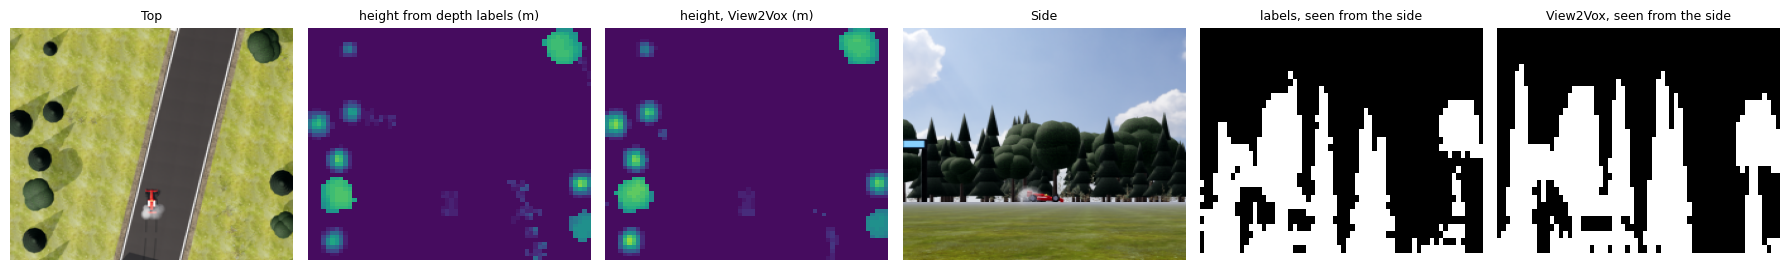

In [6]:
model.eval()
with torch.no_grad():
    outs = [model(torch.stack([views(r) for r in traj[a:a + 8]]).to(dev)) for a in range(0, len(traj), 8)]
pred = torch.cat([o[0] for o in outs]).cpu().numpy() > 0                            # (T, 64, 64, 32)
pred_rgb = torch.cat([o[1] for o in outs]).permute(0, 2, 3, 4, 1).cpu().numpy()     # (T, 64, 64, 32, 3)
labels = [voxel_labels(r) for r in traj]
true = np.stack([l[0] for l in labels])
iou = lambda a, b: (a & b).sum() / max((a | b).sum(), 1)
both = pred & true                                                                   # cells solid in both
colour_error = np.abs(pred_rgb[both] * 255 - np.stack([l[1] for l in labels])[both]).mean()
print(f"unseen track, {len(traj)} steps | IoU {iou(pred, true):.2f} | above the ground {iou(pred[..., 1:], true[..., 1:]):.2f} "
      f"| colour error {colour_error:.1f} / 255")

height = lambda o: np.where(o.any(-1), NH - np.argmax(o[..., ::-1], -1), 0) * DH     # top of each column, in metres
from_side = lambda o: o.any(1).T[::-1, ::-1]                                         # seen from the right: forward to the right
k = 40
fig, ax = plt.subplots(1, 6, figsize=(18, 2.8))
for a, im, t in zip(ax, [traj[k]["img"]["top"], height(true[k]), height(pred[k]), traj[k]["img"]["side"], from_side(true[k]), from_side(pred[k])],
                    ["Top", "height from depth labels (m)", "height, View2Vox (m)", "Side", "labels, seen from the side", "View2Vox, seen from the side"]):
    a.imshow(im, aspect="auto", vmin=0 if im.ndim == 2 else None, vmax=NH * DH if im.dtype != bool and im.ndim == 2 else None,
             cmap="viridis" if im.ndim == 2 and im.dtype != bool else "gray")
    a.set_title(t); a.axis("off")
plt.tight_layout(); plt.show()

### Read the voxels out into the FPV: sparse voxels and 3DGS

Both read-outs draw voxels nearest first:
- **Sparse voxels:** each voxel is an opaque square about its projected size, and a pixel keeps the first colour it gets.
- **3DGS:** each voxel is a round 3D Gaussian (sigma = half a cell), blended front to back.

Placing the grid in the world and projecting into the FPV uses the camera dicts. Learning that part is the next step; here we only check that the predicted voxels look like the scene.

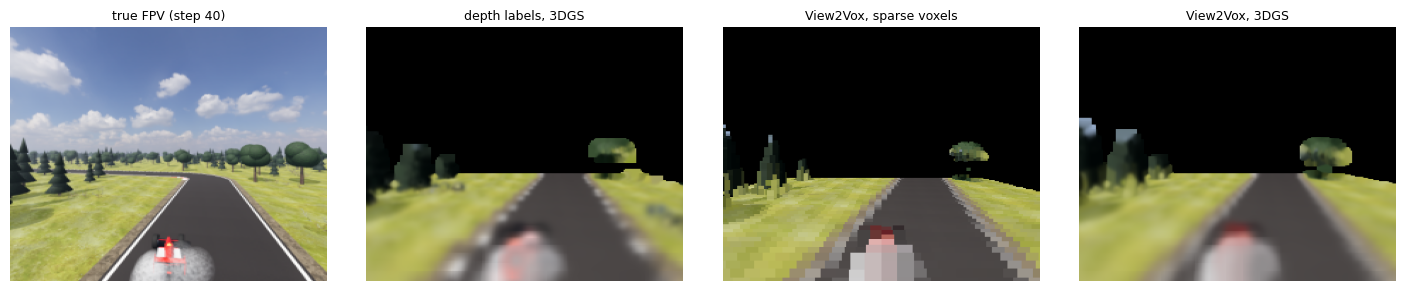

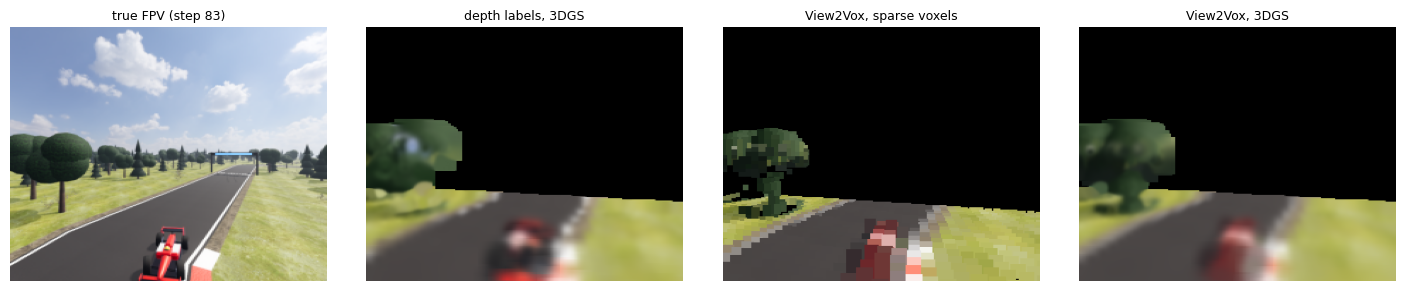

In [7]:
def to_fpv(cam, P):
    """World points -> pixel (u, v) in the S x S FPV, depth z along its viewing axis, and its focal length (render px)."""
    pos, fwd, right, up = axes(cam)
    f = (RENDER_H / 2) / np.tan(np.radians(cam["fov"]) / 2)         # fov is vertical
    d = P - pos
    z = d @ fwd
    return (RENDER_W / 2 + f * (d @ right) / z) * S / RENDER_W, (RENDER_H / 2 - f * (d @ up) / z) * S / RENDER_H, z, f

def render(cam, P, rgb, gaussian, cell=1.0):
    """Draw voxels into the FPV, nearest first.
    gaussian=False: sparse voxels, opaque squares of their projected size.
    gaussian=True:  3DGS, round Gaussians (sigma = half a cell) blended front to back."""
    u, v, z, f = to_fpv(cam, P)
    img, T = np.zeros((S, S, 3)), np.ones((S, S))                   # colour so far, light still passing through
    for n in np.argsort(z):
        if z[n] < cam["near"]:
            continue
        sx, sy = 0.5 * cell * f / z[n] * S / RENDER_W, 0.5 * cell * f / z[n] * S / RENDER_H   # half-size in pixels
        sx, sy = max(sx, 0.5), max(sy, 0.5)
        R = int(min(3 * max(sx, sy), 12)) + 1
        y0, y1, x0, x1 = max(int(v[n]) - R, 0), min(int(v[n]) + R + 1, S), max(int(u[n]) - R, 0), min(int(u[n]) + R + 1, S)
        if y0 >= y1 or x0 >= x1:                                      # off screen
            continue
        ys, xs = np.mgrid[y0:y1, x0:x1]
        dx, dy = xs + 0.5 - u[n], ys + 0.5 - v[n]
        a = 0.95 * np.exp(-0.5 * ((dx / sx) ** 2 + (dy / sy) ** 2)) if gaussian else ((abs(dx) <= sx) & (abs(dy) <= sy)) * 1.0
        img[ys, xs] += (T[ys, xs] * a)[..., None] * rgb[n]
        T[ys, xs] *= 1 - a
    return (img / np.maximum(1 - T, 1e-6)[..., None]).clip(0, 1)

def cells_to_world(top_cam, occ, col):
    """Solid grid cells -> world points (cell centres) and colours. Top looks straight down from height pos[1]."""
    i, j, k = np.nonzero(occ)
    P = ortho_to_world(top_cam, (i + 0.5) * S / G - 0.5, (j + 0.5) * S / G - 0.5,
                       top_cam["pos"][1] - (k + 0.5) * DH)
    return P, col[i, j, k]

for k in (40, LAST):
    cams = traj[k]["cams"]
    P_true, c_true = cells_to_world(cams["top"], true[k], labels[k][1] / 255)
    P_pred, c_pred = cells_to_world(cams["top"], pred[k], pred_rgb[k])
    show([traj[k]["img"]["fpv"], render(cams["fpv"], P_true, c_true, True),
          render(cams["fpv"], P_pred, c_pred, False), render(cams["fpv"], P_pred, c_pred, True)],
         [f"true FPV (step {k})", "depth labels, 3DGS", "View2Vox, sparse voxels", "View2Vox, 3DGS"], size=3.6)

### What this shows

The model trained for 5 minutes (2,000 steps on 360 frames from three other tracks, 3.7M parameters). On section 1's unseen track, scored against the depth labels, it gets **occupancy IoU 0.74 overall and 0.42 above the ground**, with colour error 10.6 / 255 on cells that are solid in both.

- **Shapes:** trees appear in the right places at about the right heights. In the sparse-voxel read-out, the step-83 tree even shows a crown on a trunk.
- **Colours:** the road, kerbs, grass and the red car come out right, because every cell's colour is picked from what the three views show there.
- **The "depth labels, 3DGS" panel** shows what a perfect prediction would look like.

For comparison, the first version reached 0.59 / 0.29: a small model (126k parameters), 64 × 64 inputs, 600 steps, and colours predicted from scratch. It rendered the car brown and produced floating blocks.

**Not done here:**
- **Memory over time:** each step is predicted on its own.
- **Learning the FPV camera:** the read-out still places and projects the grid with the camera dicts.
- **Other envs:** the learned line-up fixes MultiCar's framing, so unseen framings would need it predicted from the images.